<center><img src="https://i.imgur.com/zRrFdsf.png" width="700"></center>

## The First GDF

With the help of **geopandas** and GitHub, we will bring the **Spain comunities**

Declaramos variables en base a España y sus comunidades.

In [381]:
import geopandas as gpd

linkGitSession='http://github.com/rodrigosalazarl-GH/LISA_SPAIN/raw/main/'
linkEspAndComunidades='gadm41_ESP_shp.zip'

fullLinkEspAndComunidades=linkGitSession+linkEspAndComunidades
EspAndComunidades=gpd.read_file(fullLinkEspAndComunidades)

/usr/local/lib/python3.13/dist-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'gadm41_ESP_shp.zip': 'gadm41_ESP_0' (default), 'gadm41_ESP_1', 'gadm41_ESP_2'. Specify layer parameter to avoid this warning.
  result = read_func(


We have the GDF. Let's visit it:

In [382]:

type(EspAndComunidades)

geopandas.geodataframe.GeoDataFrame

In [383]:
# dimensions
EspAndComunidades.shape

(1, 3)

In [384]:
# names
EspAndComunidades.columns

Index(['GID_0', 'COUNTRY', 'geometry'], dtype='object')

In [385]:
# any missing values?
EspAndComunidades[EspAndComunidades.isna().any(axis=1)]

,GID_0,COUNTRY,geometry


In [386]:
# data types in the GDF
EspAndComunidades.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   GID_0     1 non-null      object  
 1   COUNTRY   1 non-null      object  
 2   geometry  1 non-null      geometry
dtypes: geometry(1), object(2)
memory usage: 156.0+ bytes


In [387]:
# some content
EspAndComunidades.head()

,GID_0,COUNTRY,geometry
0,ESP,Spain,"MULTIPOLYGON (((-17.96319 27.69042, -17.96319 ..."


All the previous commands exist and work the same if you had a DF from pandas. But now we have a new column type: **geometry**, and we can have some extra functions from _geopandas_:

In [388]:
# what geometry?
EspAndComunidades.geom_type.unique()

array(['MultiPolygon'], dtype=object)

As we have polygons, we know the map is about country borders:

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

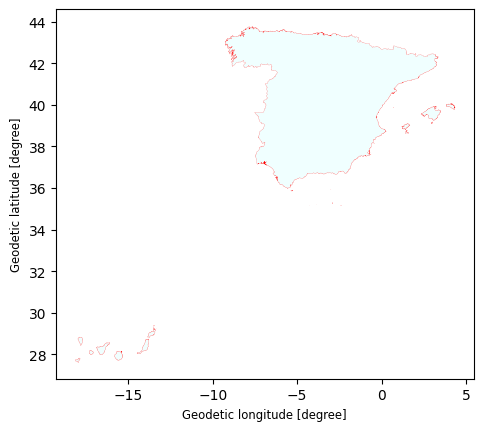

In [389]:
EspAndComunidades.plot(facecolor="azure",#color of polygon fill
               edgecolor='red', #color of border
               linewidth=0.1) #thickness of lines

## More GDFs

Let's open the other maps:

Mapa de las comunidades de España GDF

In [390]:
linkComunidadesAuto = 'comunidades/gadm41_ESP_1.shp'

fullLinkComunidadesAuto = linkGitSession + linkComunidadesAuto

comunidades = gpd.read_file(fullLinkComunidadesAuto)

This is the cities map:

You can start by creating the **base** layer, and add other maps, as layers, on top: and plot the map

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

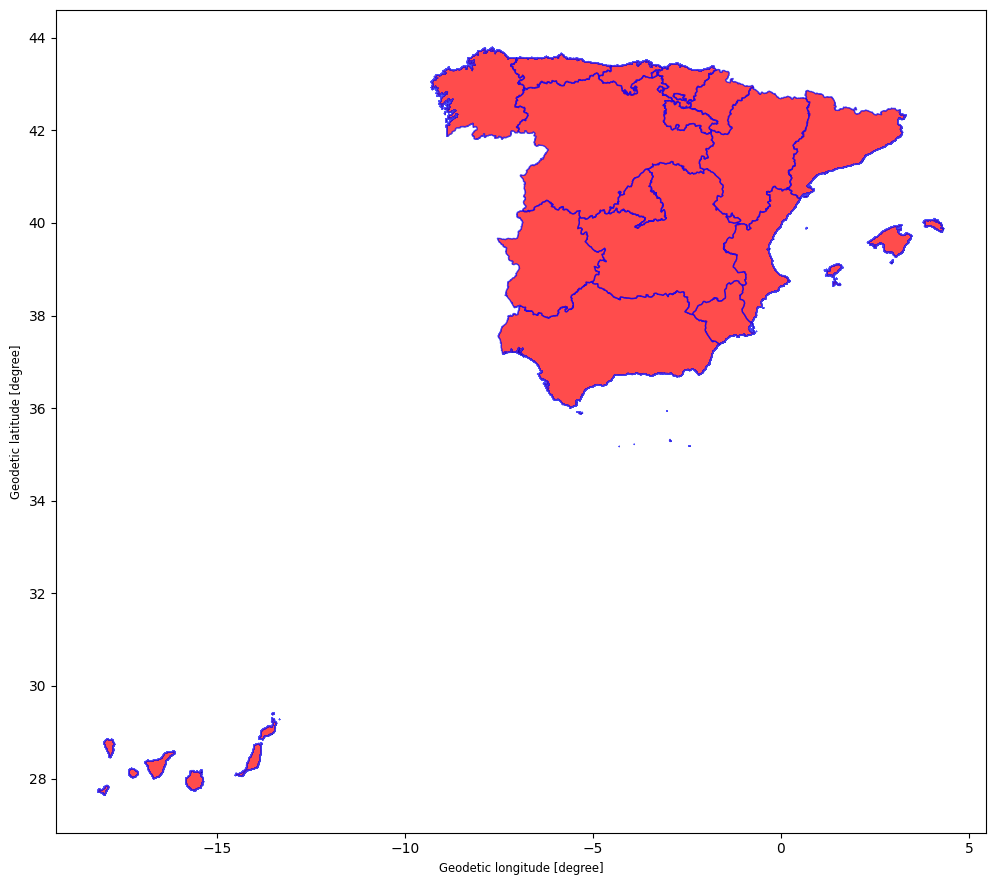

In [391]:
base = EspAndComunidades.plot(facecolor="white",
                      edgecolor='black',
                      linewidth=0.1,
                      figsize=(12,12))


comunidades.plot(marker='.', edgecolor='blue', color='red', markersize=1,alpha=0.7,
            ax=base)



# The Map Projection

We know the reality is at least in 3D, so on this screen and on piece of paper we should alter reality so the earth or parts of it can be seen in a meaningful way.

Let's find out about the way the maps we have are represented in 2D:

In [392]:
EspAndComunidades.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [393]:
comunidades.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In all the previous cases, you see a common CRS (EPSG 4326), and also that their axes are in **long** / **lat** (measured in *degrees*). The map is **NOT projected**.


In [394]:
Spain=EspAndComunidades[EspAndComunidades.COUNTRY=='Spain']

Dates Spain

In [395]:
Spain.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [396]:
Spain.crs.axis_info[0].unit_name, Spain.crs.axis_info[1].unit_name

('degree', 'degree')

Spain is pojected?

In [397]:
Spain.crs.is_projected

False

## Reprojecting

A projected CRS will have units in meters or feet (or similar). You can request a EPSG per country [here](https://epsg.io/?q=Spain+kind%3APROJCRS), but also debating with AI is good alternative. Recomendación de  la web y consulta

In [398]:
# recommended from website
Spain.to_crs(5634).crs.axis_info[0].unit_name, Spain.to_crs(5634).crs.axis_info[1].unit_name

('metre', 'metre')

In [399]:
# now this works with no warning
Spain.to_crs(5634).centroid

,0
0,POINT (2857171.01 1628196.848)


El crs projectado de España fue cambiao a 3035

In [400]:
# recommended from Gemini - after a long chat!
Spain.to_crs(3035).crs.axis_info[0].unit_name,Spain.to_crs(3035).crs.axis_info[1].unit_name

('metre', 'metre')

Let's keep the **EPSG: 3035**  for the the comunities and the country (SPAIN)
Guardamos la variable de Spain projected, para su usar luego

In [401]:
Spain_3035=Spain.to_crs(3035)
comunidades_Spain_3035=comunidades[comunidades.COUNTRY=='Spain'].to_crs(3035)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

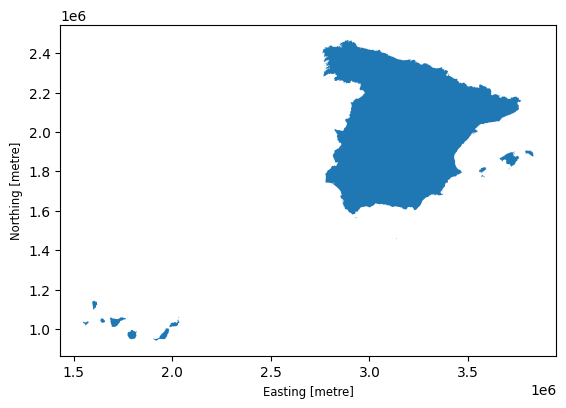

In [402]:
Spain_3035.plot()

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

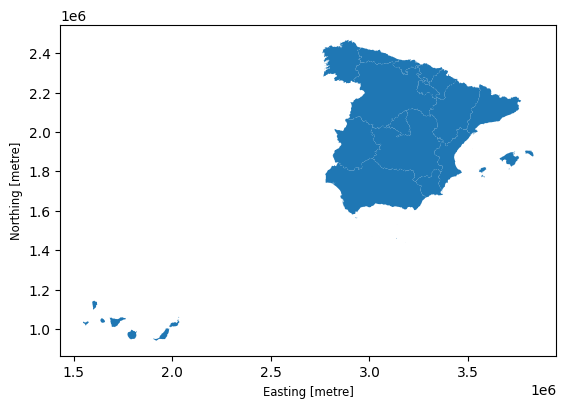

In [403]:
comunidades_Spain_3035.plot()

#Import DF
Archivo que contiene como dato el **RIESGO DE POBREZA DE LAS COMUNIDADES AUTONOMAS**

Extraido de https://datosmacro.expansion.com/demografia/riesgo-pobreza/espana-comunidades-autonomas


In [404]:
import pandas as pd

linkGitSession='https://github.com/rodrigosalazarl-GH/LISA_SPAIN/raw/main/'
someDataLink='data/Comunidad%2CPobreza.csv'

someData=pd.read_csv(linkGitSession+someDataLink, sep=';', engine='python')

## data available
someData.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   comunidad  18 non-null     object 
 1   pobreza    18 non-null     float64
dtypes: float64(1), object(1)
memory usage: 420.0+ bytes


Muestra la información del DF

In [405]:
someData.head()

,comunidad,pobreza
0,Andalucía,27.7
1,Aragón,13.6
2,Asturias,17.2
3,Cantabria,13.9
4,Castilla y León,19.8


Show the column "comunities as NAME_1:" para GDF

In [406]:
comunidades_Spain_3035.NAME_1.head()

,NAME_1
0,Andalucía
1,Aragón
2,Cantabria
3,Castilla-La Mancha
4,Castilla y León


Show the column "comunities as comunidad:" para DF

In [407]:
someData.comunidad.head()

,comunidad
0,Andalucía
1,Aragón
2,Asturias
3,Cantabria
4,Castilla y León


MUestra el GDF, la cabecera

In [408]:
print(comunidades_Spain_3035.columns)
display(comunidades_Spain_3035.head())

Index(['GID_1', 'GID_0', 'COUNTRY', 'NAME_1', 'VARNAME_1', 'NL_NAME_1',
       'TYPE_1', 'ENGTYPE_1', 'CC_1', 'HASC_1', 'ISO_1', 'geometry'],
      dtype='object')


,GID_1,GID_0,COUNTRY,NAME_1,VARNAME_1,NL_NAME_1,TYPE_1,ENGTYPE_1,CC_1,HASC_1,ISO_1,geometry
0,ESP.1_1,ESP,Spain,Andalucía,Andalousie|Andaluc¡a|Andalusien|,NA,Comunidad Autónoma,Autonomous Community,01,ES.AN,NA,"MULTIPOLYGON (((3140224.434 1531298.763, 31402..."
1,ESP.2_1,ESP,Spain,Aragón,Aragão|Aragó|Aragón|Aragona|Arag,NA,Comunidad Autónoma,Autonomous Community,15,ES.AR,NA,"POLYGON ((3394510.47 1933341.623, 3394857.557 ..."
2,ESP.3_1,ESP,Spain,Cantabria,Cantàbria|Cantábria|Cantabrie|Ka,NA,Comunidad Autónoma,Autonomous Community,06,ES.CB,ES-CB,"MULTIPOLYGON (((3186946.783 2305680.547, 31868..."
3,ESP.4_1,ESP,Spain,Castilla-La Mancha,Castela-La Mancha|Castela-Mancha,NA,Comunidad Autónoma,Autonomous Community,08,ES.CM,ES-CM,"MULTIPOLYGON (((3320725.971 1797144.007, 33194..."
4,ESP.5_1,ESP,Spain,Castilla y León,Castile and Leon|Castela e Leão|,NA,Comunidad Autónoma,Autonomous Community,07,ES.CL,NA,"MULTIPOLYGON (((2995681.931 2042242.654, 29957..."


Observando las columnas, `NAME_1` en `comunidades_Spain_3035` parece ser el nombre de la comunidad autónoma. Así que podemos hacer el merge usando `NAME_1` de `comunidades_Spain_3035` y `comunidad` de `someData`.

In [410]:
comunidades_Spain_3035.rename(columns={'NAME_1':'comunidad'},inplace=True)

Buscamos coincidencia entre ambas columnas comunidad.

In [411]:
onlyDF=set(someData.comunidad)- set(comunidades_Spain_3035.comunidad)
onlyGDF=set(comunidades_Spain_3035.comunidad)- set(someData.comunidad)

Coincidencia no encoontradas para el DF

In [412]:
onlyDF

{'Asturias', 'Canarias', 'Navarra'}

Instalacion the fuzz merging

In [413]:
!pip install thefuzz

Extraemos los que tienen mejor resultado de coincidencia

In [414]:
from thefuzz.process import extractOne as mejor

In [415]:
mejor('Asturias',onlyGDF)

('Principado de Asturias', 90)

In [416]:
[(comunidad, mejor(comunidad,onlyGDF)) for comunidad in onlyDF]

[('Asturias', ('Principado de Asturias', 90)),
 ('Canarias', ('Islas Canarias', 90)),
 ('Navarra', ('Comunidad Foral de Navarra', 90))]

In [417]:
[(comunidad, mejor(comunidad,onlyGDF)[0],mejor(comunidad,onlyGDF)[1]) for comunidad in onlyDF]

[('Asturias', 'Principado de Asturias', 90),
 ('Canarias', 'Islas Canarias', 90),
 ('Navarra', 'Comunidad Foral de Navarra', 90)]

In [418]:
pd.DataFrame([(comunidad, mejor(comunidad,onlyGDF)[0],mejor(comunidad,onlyGDF)[1]) for comunidad in onlyDF])

,0,1,2
0,Asturias,Principado de Asturias,90
1,Canarias,Islas Canarias,90
2,Navarra,Comunidad Foral de Navarra,90


In [419]:
pd.DataFrame([(comunidad, mejor(comunidad,onlyGDF)[0],mejor(comunidad,onlyGDF)[1]) for comunidad in onlyDF]).sort_values(by=2)

,0,1,2
0,Asturias,Principado de Asturias,90
1,Canarias,Islas Canarias,90
2,Navarra,Comunidad Foral de Navarra,90


In [420]:
onlyDF=set(someData.comunidad)- set(comunidades_Spain_3035.comunidad)
onlyGDF=set(comunidades_Spain_3035.comunidad)- set(someData.comunidad)

In [421]:
pd.DataFrame([(comunidad, mejor(comunidad,onlyGDF)[0],mejor(comunidad,onlyGDF)[1]) for comunidad in onlyDF]).sort_values(2)

,0,1,2
0,Asturias,Principado de Asturias,90
1,Canarias,Islas Canarias,90
2,Navarra,Comunidad Foral de Navarra,90


In [422]:
changesToDF={comunidad: mejor(comunidad,onlyGDF)[0] for comunidad in onlyDF}
changesToDF

{'Asturias': 'Principado de Asturias',
 'Canarias': 'Islas Canarias',
 'Navarra': 'Comunidad Foral de Navarra'}

In [423]:
someData.replace(to_replace={'comunidad':changesToDF},inplace=True)

Coincidnecia entre todos los datos de las columnas comunidad

In [424]:
onlyDF=set(someData.comunidad)- set(comunidades_Spain_3035.comunidad)
onlyGDF=set(comunidades_Spain_3035.comunidad)- set(someData.comunidad)
[(comunidad, mejor(comunidad,onlyGDF)) for comunidad in onlyDF]

[]

In [425]:
comunidades_esp=comunidades_Spain_3035.merge(someData, on='comunidad')

In [427]:
comunidades_esp.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   GID_1      18 non-null     object  
 1   GID_0      18 non-null     object  
 2   COUNTRY    18 non-null     object  
 3   comunidad  18 non-null     object  
 4   VARNAME_1  18 non-null     object  
 5   NL_NAME_1  18 non-null     object  
 6   TYPE_1     18 non-null     object  
 7   ENGTYPE_1  18 non-null     object  
 8   CC_1       18 non-null     object  
 9   HASC_1     18 non-null     object  
 10  ISO_1      18 non-null     object  
 11  geometry   18 non-null     geometry
 12  pobreza    18 non-null     float64 
dtypes: float64(1), geometry(1), object(11)
memory usage: 2.0+ KB


In [367]:
comunidades_esp.to_file("worldindicators.json")

FIN DEL MERGE

In [428]:
!pip show pysal pandas geopandas

Name: pysal
Version: 25.7
Summary: Meta Package for PySAL - A library of spatial analysis functions
Home-page: 
Author: 
Author-email: Serge Rey <sjsrey@gmail.com>, Levi Wolf <levi.john.wolf@gmail.com>
License: BSD 3-Clause
Location: /usr/local/lib/python3.13/dist-packages
Requires: access, beautifulsoup4, esda, geopandas, giddy, inequality, libpysal, mapclassify, mgwr, momepy, numpy, packaging, pandas, platformdirs, pointpats, requests, scikit-learn, scipy, segregation, shapely, spaghetti, spglm, spint, splot, spopt, spreg, tobler
Required-by: 
---
Name: pandas
Version: 2.2.3
Summary: Powerful data structures for data analysis, time series, and statistics
Home-page: https://pandas.pydata.org
Author: 
Author-email: The Pandas Development Team <pandas-dev@python.org>
License: BSD 3-Clause License

Copyright (c) 2008-2011, AQR Capital Management, LLC, Lambda Foundry, Inc. and PyData Development Team
All rights reserved.

Copyright (c) 2011-2023, Open source contributors.

Redistribution 

In [429]:
!pip install pysal

In [430]:
comunidades_esp.set_index('comunidad', inplace=True)
comunidades_esp.head()

,GID_1,GID_0,COUNTRY,VARNAME_1,NL_NAME_1,TYPE_1,ENGTYPE_1,CC_1,HASC_1,ISO_1,geometry,pobreza
comunidad,,,,,,,,,,,,
Andalucía,ESP.1_1,ESP,Spain,Andalousie|Andaluc¡a|Andalusien|,NA,Comunidad Autónoma,Autonomous Community,01,ES.AN,NA,"MULTIPOLYGON (((3140224.434 1531298.763, 31402...",27.7
Aragón,ESP.2_1,ESP,Spain,Aragão|Aragó|Aragón|Aragona|Arag,NA,Comunidad Autónoma,Autonomous Community,15,ES.AR,NA,"POLYGON ((3394510.47 1933341.623, 3394857.557 ...",13.6
Cantabria,ESP.3_1,ESP,Spain,Cantàbria|Cantábria|Cantabrie|Ka,NA,Comunidad Autónoma,Autonomous Community,06,ES.CB,ES-CB,"MULTIPOLYGON (((3186946.783 2305680.547, 31868...",13.9
Castilla-La Mancha,ESP.4_1,ESP,Spain,Castela-La Mancha|Castela-Mancha,NA,Comunidad Autónoma,Autonomous Community,08,ES.CM,ES-CM,"MULTIPOLYGON (((3320725.971 1797144.007, 33194...",25.9
Castilla y León,ESP.5_1,ESP,Spain,Castile and Leon|Castela e Leão|,NA,Comunidad Autónoma,Autonomous Community,07,ES.CL,NA,"MULTIPOLYGON (((2995681.931 2042242.654, 29957...",19.8


In [431]:
import pandas as pd

# Configuramos pandas para que muestre todas las filas del GeoDataFrame comunidades_esp
with pd.option_context('display.max_rows', None):
    display(comunidades_esp)

,GID_1,GID_0,COUNTRY,VARNAME_1,NL_NAME_1,TYPE_1,ENGTYPE_1,CC_1,HASC_1,ISO_1,geometry,pobreza
comunidad,,,,,,,,,,,,
Andalucía,ESP.1_1,ESP,Spain,Andalousie|Andaluc¡a|Andalusien|,NA,Comunidad Autónoma,Autonomous Community,01,ES.AN,NA,"MULTIPOLYGON (((3140224.434 1531298.763, 31402...",27.7
Aragón,ESP.2_1,ESP,Spain,Aragão|Aragó|Aragón|Aragona|Arag,NA,Comunidad Autónoma,Autonomous Community,15,ES.AR,NA,"POLYGON ((3394510.47 1933341.623, 3394857.557 ...",13.6
Cantabria,ESP.3_1,ESP,Spain,Cantàbria|Cantábria|Cantabrie|Ka,NA,Comunidad Autónoma,Autonomous Community,06,ES.CB,ES-CB,"MULTIPOLYGON (((3186946.783 2305680.547, 31868...",13.9
Castilla-La Mancha,ESP.4_1,ESP,Spain,Castela-La Mancha|Castela-Mancha,NA,Comunidad Autónoma,Autonomous Community,08,ES.CM,ES-CM,"MULTIPOLYGON (((3320725.971 1797144.007, 33194...",25.9
Castilla y León,ESP.5_1,ESP,Spain,Castile and Leon|Castela e Leão|,NA,Comunidad Autónoma,Autonomous Community,07,ES.CL,NA,"MULTIPOLYGON (((2995681.931 2042242.654, 29957...",19.8
Cataluña,ESP.6_1,ESP,Spain,Catalogna|Catalogne|Catalonia|Ca,NA,Comunidad Autónoma,Autonomous Community,09,ES.CT,NA,"MULTIPOLYGON (((3509568.598 1990154.551, 35094...",14.3
Ceuta y Melilla,ESP.7_1,ESP,Spain,NA,NA,Ciudad Autónoma,Autonomous City,19,ES.ML,NA,"MULTIPOLYGON (((3181474.918 1439885.947, 31815...",38.2
Comunidad de Madrid,ESP.8_1,ESP,Spain,Madrid|Communauté de Madrid| Com,NA,Comunidad Autónoma,Autonomous Community,NA,ES.MD,NA,"MULTIPOLYGON (((3135875.888 1977029.997, 31356...",12.7
Comunidad Foral de Navarra,ESP.9_1,ESP,Spain,Communauté forale de Navarre|Com,NA,Comunidad Autónoma,Autonomous Community,15,ES.NA,NA,"POLYGON ((3359007.179 2167900.746, 3358600.856...",12.3


In [433]:
all_comunidades=['Andalucía','Aragón','Principado de Asturias','Cantabria','Castilla y León','Castilla-La Mancha','Islas Canarias','Cataluña','Ceuta y Melilla','Extremadura','Galicia','Islas Baleares','Región de Murcia','Comunidad de Madrid','Comunidad Foral de Navarra','País Vasco','La Rioja','Comunidad Valenciana']

In [442]:
# 1. Filtramos directamente desde el GeoDataFrame del merge que ya tiene configurado el índice 'comunidad'
sub_esp = comunidades_esp[comunidades_esp.index.isin(all_comunidades)]
sub_esp

,GID_1,GID_0,COUNTRY,VARNAME_1,NL_NAME_1,TYPE_1,ENGTYPE_1,CC_1,HASC_1,ISO_1,geometry,pobreza
comunidad,,,,,,,,,,,,
Andalucía,ESP.1_1,ESP,Spain,Andalousie|Andaluc¡a|Andalusien|,NA,Comunidad Autónoma,Autonomous Community,01,ES.AN,NA,"MULTIPOLYGON (((3140224.434 1531298.763, 31402...",27.7
Aragón,ESP.2_1,ESP,Spain,Aragão|Aragó|Aragón|Aragona|Arag,NA,Comunidad Autónoma,Autonomous Community,15,ES.AR,NA,"POLYGON ((3394510.47 1933341.623, 3394857.557 ...",13.6
Cantabria,ESP.3_1,ESP,Spain,Cantàbria|Cantábria|Cantabrie|Ka,NA,Comunidad Autónoma,Autonomous Community,06,ES.CB,ES-CB,"MULTIPOLYGON (((3186946.783 2305680.547, 31868...",13.9
Castilla-La Mancha,ESP.4_1,ESP,Spain,Castela-La Mancha|Castela-Mancha,NA,Comunidad Autónoma,Autonomous Community,08,ES.CM,ES-CM,"MULTIPOLYGON (((3320725.971 1797144.007, 33194...",25.9
Castilla y León,ESP.5_1,ESP,Spain,Castile and Leon|Castela e Leão|,NA,Comunidad Autónoma,Autonomous Community,07,ES.CL,NA,"MULTIPOLYGON (((2995681.931 2042242.654, 29957...",19.8
Cataluña,ESP.6_1,ESP,Spain,Catalogna|Catalogne|Catalonia|Ca,NA,Comunidad Autónoma,Autonomous Community,09,ES.CT,NA,"MULTIPOLYGON (((3509568.598 1990154.551, 35094...",14.3
Ceuta y Melilla,ESP.7_1,ESP,Spain,NA,NA,Ciudad Autónoma,Autonomous City,19,ES.ML,NA,"MULTIPOLYGON (((3181474.918 1439885.947, 31815...",38.2
Comunidad de Madrid,ESP.8_1,ESP,Spain,Madrid|Communauté de Madrid| Com,NA,Comunidad Autónoma,Autonomous Community,NA,ES.MD,NA,"MULTIPOLYGON (((3135875.888 1977029.997, 31356...",12.7
Comunidad Foral de Navarra,ESP.9_1,ESP,Spain,Communauté forale de Navarre|Com,NA,Comunidad Autónoma,Autonomous Community,15,ES.NA,NA,"POLYGON ((3359007.179 2167900.746, 3358600.856...",12.3


In [444]:
sub_esp.geometry.apply\
(lambda comunida: sub_esp.distance(comunida)/1000)

comunidad,Andalucía,Aragón,Cantabria,Castilla-La Mancha,Castilla y León,Cataluña,Ceuta y Melilla,Comunidad de Madrid,Comunidad Foral de Navarra,Comunidad Valenciana,Extremadura,Galicia,Islas Baleares,Islas Canarias,La Rioja,País Vasco,Principado de Asturias,Región de Murcia
comunidad,,,,,,,,,,,,,,,,,,
Andalucía,0.000000,203.151274,452.880113,0.000000,150.622460,338.464819,15.384176,159.229996,385.494827,86.786523,0.000000,392.803407,295.951712,1004.332519,379.720002,436.169027,474.117896,0.000000
Aragón,203.151274,0.000000,176.013323,0.000000,0.000000,0.000000,529.340549,106.834874,0.000000,0.000000,266.668734,396.291402,195.528383,1586.463645,0.000000,71.798005,262.467233,123.443162
Cantabria,452.880113,176.013323,0.000000,171.400810,0.000000,315.629601,763.116708,180.434456,86.085301,357.035694,294.843985,160.170105,599.934524,1672.811854,61.402508,0.000000,0.000000,501.224758
Castilla-La Mancha,0.000000,0.000000,171.400810,0.000000,0.000000,138.374265,281.406780,0.000000,88.346050,0.000000,0.000000,248.968295,181.505064,1267.658366,75.584977,129.219574,240.104760,0.000000
Castilla y León,150.622460,0.000000,0.000000,0.000000,0.000000,175.494681,460.037456,0.000000,3.619883,115.187848,0.000000,0.000000,361.583117,1321.377920,0.000000,0.000000,0.000000,267.750798
Cataluña,338.464819,0.000000,315.629601,138.374265,175.494681,0.000000,639.623838,280.818082,113.483989,0.000000,436.470305,590.897220,167.871928,1738.261660,175.429351,201.787231,425.560312,239.537959
Ceuta y Melilla,15.384176,529.340549,763.116708,281.406780,460.037456,639.623838,0.000000,455.762045,732.123072,325.942869,235.152395,678.378178,507.627558,1024.857660,702.626368,758.444172,781.163035,250.201823
Comunidad de Madrid,159.229996,106.834874,180.434456,0.000000,0.000000,280.818082,455.762045,0.000000,163.983094,136.539099,65.380017,268.381534,385.476286,1420.477960,107.685936,163.065542,245.380573,212.543543
Comunidad Foral de Navarra,385.494827,0.000000,86.085301,88.346050,3.619883,113.483989,732.123072,163.983094,0.000000,162.552914,344.907718,349.084201,393.539766,1716.747868,0.000000,0.000000,181.633346,350.352844


(941803.6818975774, 2468122.5729154013)

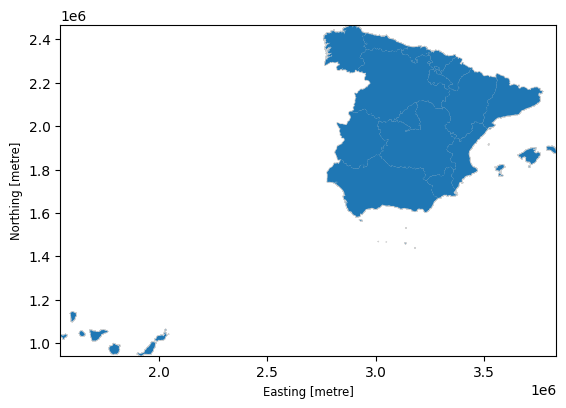

In [449]:
# Nos aseguramos de utilizar comunidades_esp como base para graficar con los datos del merge
minx, miny, maxx, maxy = sub_esp.total_bounds

base = comunidades_esp.plot(facecolor='white', edgecolor='lightgrey')
sub_esp.plot(ax=base)

base.set_xlim(minx, maxx)
base.set_ylim(miny, maxy)

In [450]:
from libpysal.graph import Graph

# also for reproducibility!
from numpy.random import seed
seed(49)

**ROOK**

In [455]:
# Filtramos correctamente usando el índice de 'comunidades_esp'
esp_selected = comunidades_esp[
    comunidades_esp.index.isin(all_comunidades)
].copy()

In [456]:
comunidades_esp.index.value_counts()

,count
comunidad,
Andalucía,1
Aragón,1
Cantabria,1
Castilla-La Mancha,1
Castilla y León,1
Cataluña,1
Ceuta y Melilla,1
Comunidad de Madrid,1
Comunidad Foral de Navarra,1


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

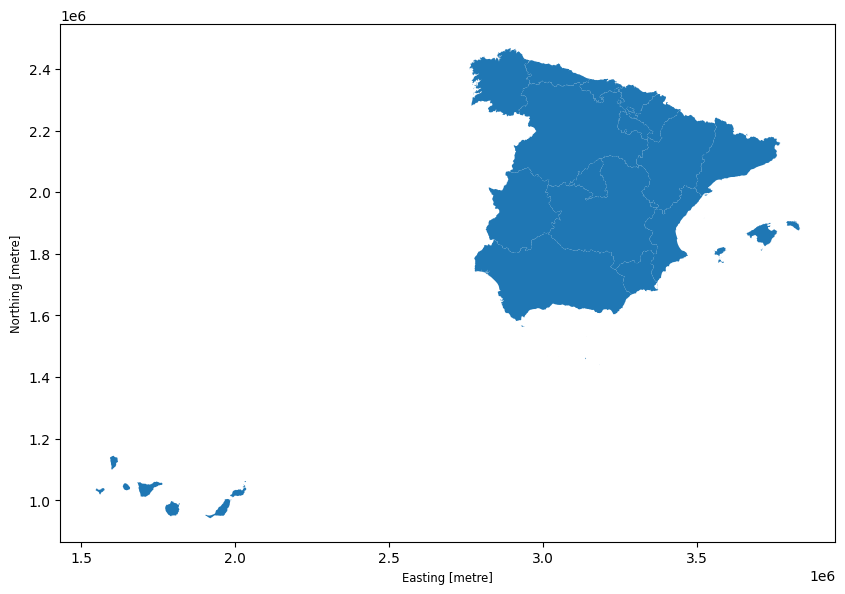

In [459]:
esp_selected.plot(figsize=(10, 10))

In [460]:
esp_selected.crs

<Projected CRS: EPSG:3035>
Name: ETRS89-extended / LAEA Europe
Axis Info [cartesian]:
- Y[north]: Northing (metre)
- X[east]: Easting (metre)
Area of Use:
- name: Europe - European Union (EU) countries and candidates. Europe - onshore and offshore: Albania; Andorra; Austria; Belgium; Bosnia and Herzegovina; Bulgaria; Croatia; Cyprus; Czechia; Denmark; Estonia; Faroe Islands; Finland; France; Germany; Gibraltar; Greece; Hungary; Iceland; Ireland; Italy; Kosovo; Latvia; Liechtenstein; Lithuania; Luxembourg; Malta; Monaco; Montenegro; Netherlands; North Macedonia; Norway including Svalbard and Jan Mayen; Poland; Portugal including Madeira and Azores; Romania; San Marino; Serbia; Slovakia; Slovenia; Spain including Canary Islands; Sweden; Switzerland; Türkiye (Turkey); United Kingdom (UK) including Channel Islands and Isle of Man; Vatican City State.
- bounds: (-35.58, 24.6, 44.83, 84.73)
Coordinate Operation:
- name: Europe Equal Area 2001
- method: Lambert Azimuthal Equal Area
Datum: Eur

In [461]:
esp_selected.crs.is_projected

True

In [462]:
rook=Graph.build_contiguity(esp_selected, rook=True) # rook by default

In [463]:
rook=rook.transform("r")

In [464]:
rook.adjacency

focal                   neighbor            
Andalucía               Castilla-La Mancha      0.333333
                        Extremadura             0.333333
                        Región de Murcia        0.333333
Aragón                  Castilla-La Mancha      0.166667
                        Castilla y León         0.166667
                                                  ...   
Principado de Asturias  Castilla y León         0.333333
                        Galicia                 0.333333
Región de Murcia        Andalucía               0.333333
                        Castilla-La Mancha      0.333333
                        Comunidad Valenciana    0.333333
Name: weight, Length: 61, dtype: float64

In [466]:
import pandas as pd

rook_matrix = pd.DataFrame(
    rook.adjacency,
    index=esp_selected.index,
    columns=esp_selected.index
)

In [467]:
rook_matrix = pd.DataFrame(rook.adjacency).unstack().fillna(0)

In [468]:
rook_matrix

weight                                         \
neighbor                   Andalucía    Aragón Cantabria Castilla-La Mancha   
focal                                                                         
Andalucía                   0.000000  0.000000  0.000000           0.333333   
Aragón                      0.000000  0.000000  0.000000           0.166667   
Cantabria                   0.000000  0.000000  0.000000           0.000000   
Castilla-La Mancha          0.142857  0.142857  0.000000           0.000000   
Castilla y León             0.000000  0.111111  0.111111           0.111111   
Cataluña                    0.000000  0.500000  0.000000           0.000000   
Ceuta y Melilla             0.000000  0.000000  0.000000           0.000000   
Comunidad de Madrid         0.000000  0.000000  0.000000           0.500000   
Comunidad Foral de Navarra  0.000000  0.333333  0.000000           0.000000   
Comunidad Valenciana        0.000000  0.250000  0.000000           0.250000   
Extremadura                 0.333333  0.000000  0.000000           0.333333   
Galicia                     0.000000  0.000000  0.000000           0.000000   
Islas Baleares              0.000000  0.000000  0.000000           0.000000   
Islas Canarias              0.000000  0.000000  0.000000           0.000000   
La Rioja                    0.000000  0.250000  0.000000           0.000000   
País Vasco                  0.000000  0.000000  0.250000           0.000000   
Principado de Asturias      0.000000  0.000000  0.333333           0.000000   
Región de Murcia            0.333333  0.000000  0.000000           0.333333   

                                                                      \
neighbor                   Castilla y León  Cataluña Ceuta y Melilla   
focal                                                                  
Andalucía                         0.000000  0.000000             0.0   
Aragón                            0.166667  0.166667             0.0   
Cantabria                         0.333333  0.000000             0.0   
Castilla-La Mancha                0.142857  0.000000             0.0   
Castilla y León                   0.000000  0.000000             0.0   
Cataluña                          0.000000  0.000000             0.0   
Ceuta y Melilla                   0.000000  0.000000             0.0   
Comunidad de Madrid               0.500000  0.000000             0.0   
Comunidad Foral de Navarra        0.000000  0.000000             0.0   
Comunidad Valenciana              0.000000  0.250000             0.0   
Extremadura                       0.333333  0.000000             0.0   
Galicia                           0.500000  0.000000             0.0   
Islas Baleares                    0.000000  0.000000             0.0   
Islas Canarias                    0.000000  0.000000             0.0   
La Rioja                          0.250000  0.000000             0.0   
País Vasco                        0.250000  0.000000             0.0   
Principado de Asturias            0.333333  0.000000             0.0   
Región de Murcia                  0.000000  0.000000             0.0   

                                                                           \
neighbor                   Comunidad de Madrid Comunidad Foral de Navarra   
focal                                                                       
Andalucía                             0.000000                   0.000000   
Aragón                                0.000000                   0.166667   
Cantabria                             0.000000                   0.000000   
Castilla-La Mancha                    0.142857                   0.000000   
Castilla y León                       0.111111                   0.000000   
Cataluña                              0.000000                   0.000000   
Ceuta y Melilla                       0.000000                   0.000000   
Comunidad de Madrid                   0.000000                   0.000000   
Comunidad 

In [469]:
rook.isolates

Index(['Ceuta y Melilla', 'Islas Baleares', 'Islas Canarias'], dtype='object', name='focal')

In [470]:
len(rook.isolates)

3

In [472]:
# 1. Filtramos esp_selected para excluir los isolates identificados
esp_selected = esp_selected.drop(index=rook.isolates)

# 2. Reconstruimos el grafo de contigüidad de Rook sin los isolates
rook = Graph.build_contiguity(esp_selected, rook=True)

# 3. Normalizamos por filas (transform='r')
rook = rook.transform("r")

# 4. Verificamos que ya no queden isolates
print(f"Isolates restantes: {len(rook.isolates)}")


Isolates restantes: 0


In [473]:
#instead of
# pd.DataFrame(rook.adjacency).unstack().fillna(0)
toWideMatrix=lambda g:pd.DataFrame(g.adjacency).unstack().fillna(0)

In [476]:
import esda

lisa_rook = esda.Moran_Local(
    esp_selected['pobreza'],
    rook
)

In [477]:
esp_selected['HS_lisa_rook'] = lisa_rook.get_cluster_labels(crit_value=0.05)

In [478]:
esp_selected['HS_lisa_rook'].value_counts()

,count
HS_lisa_rook,
Insignificant,10
High-High,4
Low-Low,1


In [480]:
oldLabels = ['Insignificant', 'Low-Low', 'High-High', 'High-Low', 'Low-High']

newLabels = [
    '3 no_pattern',
    '4 coldSpot',
    '2 hotSpot',
    '1 hotOutlier',
    '5 coldOutlier'
]

labels = dict(zip(oldLabels, newLabels))

esp_selected.replace({'HS_lisa_rook': labels}, inplace=True)

In [481]:
esp_selected['HS_lisa_rook'].value_counts().sort_index()

,count
HS_lisa_rook,
2 hotSpot,4
3 no_pattern,10
4 coldSpot,1


**PRIMER MAPA**

In [482]:
import matplotlib.pyplot as plt

myColMap = plt.get_cmap('PuOr', 5)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

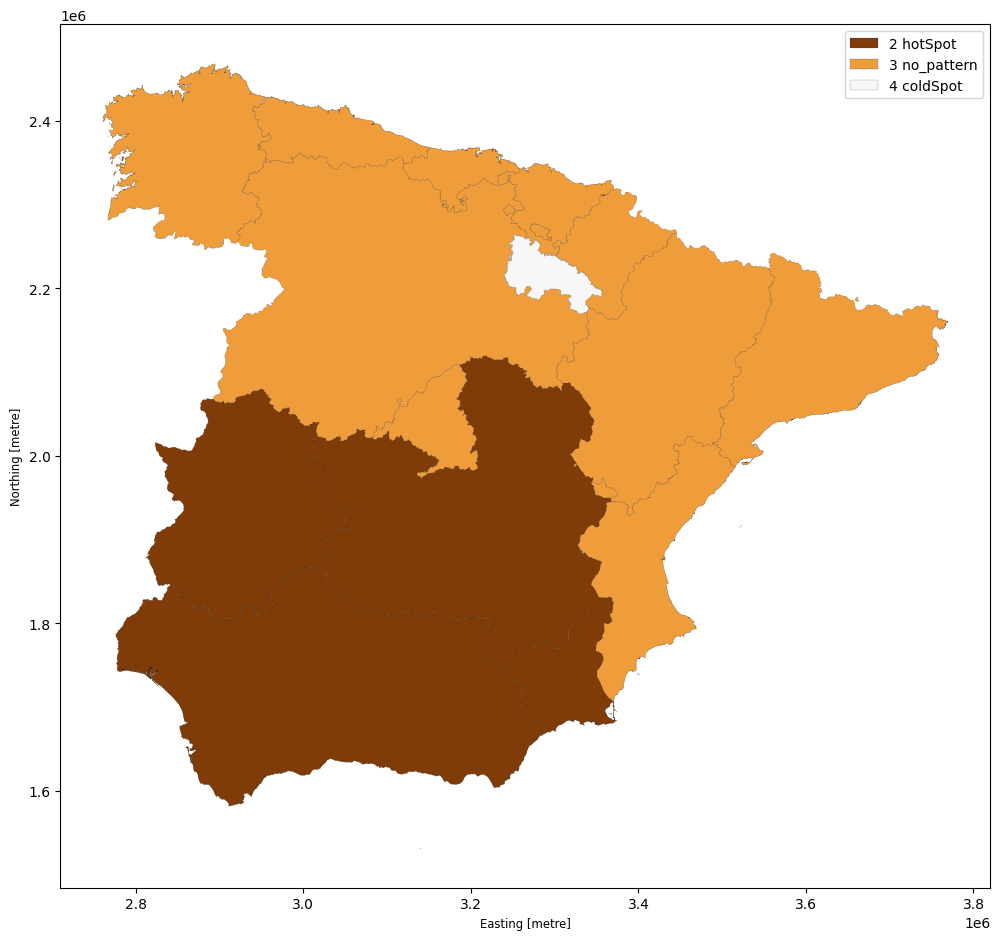

In [483]:
esp_selected.plot(
    column='HS_lisa_rook',
    categorical=True,
    cmap=myColMap,
    linewidth=0.1,
    edgecolor='k',
    legend=True,
    figsize=(12, 12)
)

**QUEEN**

In [484]:
queen = Graph.build_contiguity(esp_selected, rook=False)

# applying our procedure:

queen_Matrix=toWideMatrix(queen)
queen_Matrix

weight                                      \
neighbor                   Andalucía Aragón Cantabria Castilla-La Mancha   
focal                                                                      
Andalucía                        0.0    0.0       0.0                1.0   
Aragón                           0.0    0.0       0.0                1.0   
Cantabria                        0.0    0.0       0.0                0.0   
Castilla-La Mancha               1.0    1.0       0.0                0.0   
Castilla y León                  0.0    1.0       1.0                1.0   
Cataluña                         0.0    1.0       0.0                0.0   
Comunidad de Madrid              0.0    0.0       0.0                1.0   
Comunidad Foral de Navarra       0.0    1.0       0.0                0.0   
Comunidad Valenciana             0.0    1.0       0.0                1.0   
Extremadura                      1.0    0.0       0.0                1.0   
Galicia                          0.0    0.0       0.0                0.0   
La Rioja                         0.0    1.0       0.0                0.0   
País Vasco                       0.0    0.0       1.0                0.0   
Principado de Asturias           0.0    0.0       1.0                0.0   
Región de Murcia                 1.0    0.0       0.0                1.0   

                                                                         \
neighbor                   Castilla y León Cataluña Comunidad de Madrid   
focal                                                                     
Andalucía                              0.0      0.0                 0.0   
Aragón                                 1.0      1.0                 0.0   
Cantabria                              1.0      0.0                 0.0   
Castilla-La Mancha                     1.0      0.0                 1.0   
Castilla y León                        0.0      0.0                 1.0   
Cataluña                               0.0      0.0                 0.0   
Comunidad de Madrid                    1.0      0.0                 0.0   
Comunidad Foral de Navarra             0.0      0.0                 0.0   
Comunidad Valenciana                   0.0      1.0                 0.0   
Extremadura                            1.0      0.0                 0.0   
Galicia                                1.0      0.0                 0.0   
La Rioja                               1.0      0.0                 0.0   
País Vasco                             1.0      0.0                 0.0   
Principado de Asturias                 1.0      0.0                 0.0   
Región de Murcia                       0.0      0.0                 0.0   

                                                                            \
neighbor                   Comunidad Foral de Navarra Comunidad Valenciana   
focal                                                                        
Andalucía                                         0.0                  0.0   
Aragón                                            1.0                  1.0   
Cantabria                                         0.0                  0.0   
Castilla-La Mancha                                0.0                  1.0   
Castilla y León                                   0.0                  0.0   
Cataluña                                          0.0                  1.0   
Comunidad de Madrid                               0.0                  0.0   
Comunidad Foral de Navarra                        0.0                  0.0   
Comunidad Valenciana                              0.0                  0.0   
Extremadura                                       0.0                  0.0   
Galicia                                           0.0                  0.0   
La Rioja                                          1.0                  0.0   
País Vasco                                        1.0                  0.0   
Principado de Asturias                            0.0         

In [485]:
queen = queen.transform("r")
len(queen.isolates)

0

In [487]:
lisa_queen = esda.Moran_Local(
    esp_selected['pobreza'],
    queen
)

In [488]:
esp_selected['HS_lisa_queen'] = lisa_queen.get_cluster_labels(crit_value=0.05)

In [489]:
esp_selected['HS_lisa_queen'].value_counts()

,count
HS_lisa_queen,
Insignificant,10
High-High,4
Low-Low,1


In [490]:
oldLabels = ['Insignificant', 'Low-Low', 'High-High', 'High-Low', 'Low-High']

newLabels = [
    '3 no_pattern',
    '4 coldSpot',
    '2 hotSpot',
    '1 hotOutlier',
    '5 coldOutlier'
]

labels = dict(zip(oldLabels, newLabels))

esp_selected.replace({'HS_lisa_queen': labels}, inplace=True)

In [491]:
esp_selected['HS_lisa_queen'].value_counts().sort_index()

,count
HS_lisa_queen,
2 hotSpot,4
3 no_pattern,10
4 coldSpot,1


**SEGUNDO MAPA**

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

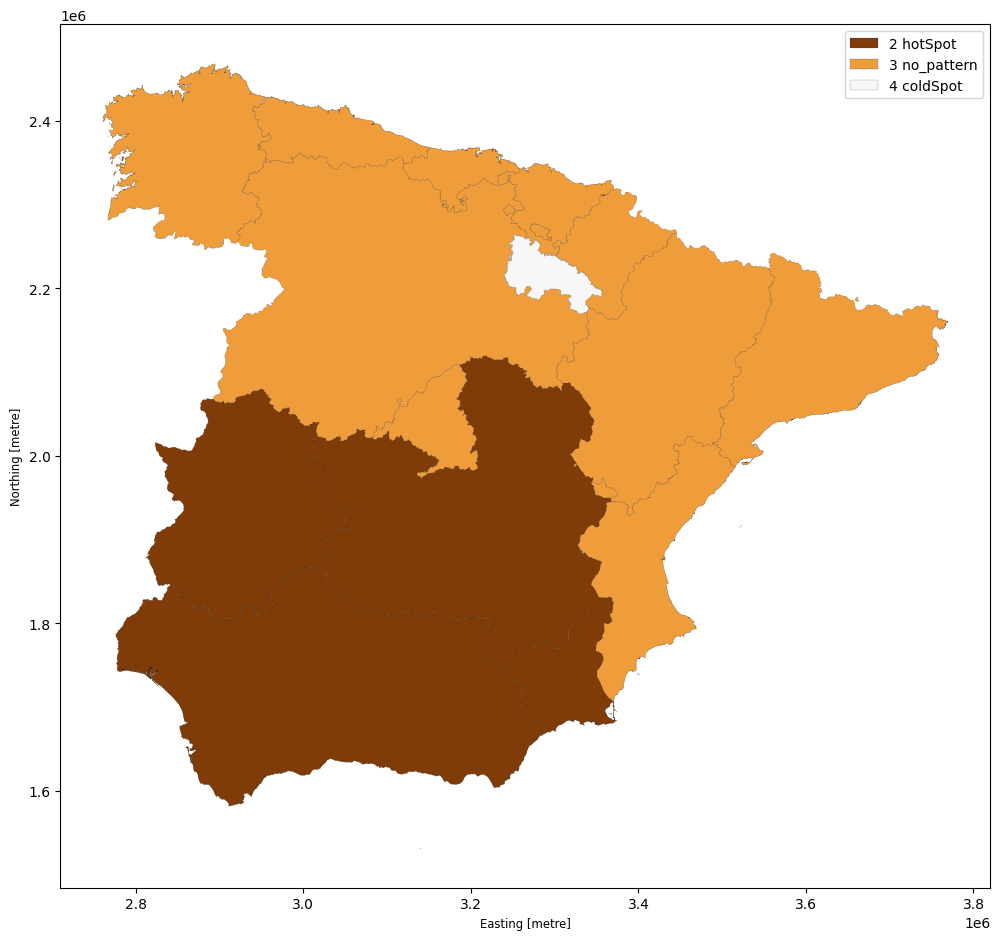

In [492]:
esp_selected.plot(
    column='HS_lisa_queen',
    categorical=True,
    cmap=myColMap,
    linewidth=0.1,
    edgecolor='k',
    legend=True,
    figsize=(12, 12)
)

**Nearest Neighbors (KNN)**

In [507]:
knn4 = Graph.build_knn(esp_selected.representative_point(), k=4)

In [508]:
knn4 = knn3.transform("r")

In [509]:
len(knn4.isolates)

0

In [510]:
lisa_knn4 = esda.Moran_Local(
    esp_selected['pobreza'],
    knn3
)

In [513]:
esp_selected['HS_lisa_knn4'] = lisa_knn4.get_cluster_labels(crit_value=0.05)

In [514]:
esp_selected['HS_lisa_knn4'].value_counts()

,count
HS_lisa_knn4,
Insignificant,12
High-High,2
Low-Low,1


In [518]:
oldLabels = ['Insignificant', 'Low-Low', 'High-High', 'High-Low', 'Low-High']

newLabels = [
    '3 no_pattern',
    '4 coldSpot',
    '2 hotSpot',
    '1 hotOutlier',
    '5 coldOutlier'
]

labels = dict(zip(oldLabels, newLabels))

esp_selected.replace({'HS_lisa_knn4': labels}, inplace=True)

In [519]:
esp_selected['HS_lisa_knn4'].value_counts().sort_index()

,count
HS_lisa_knn4,
2 hotSpot,2
3 no_pattern,12
4 coldSpot,1


**TERCER MAPA**

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

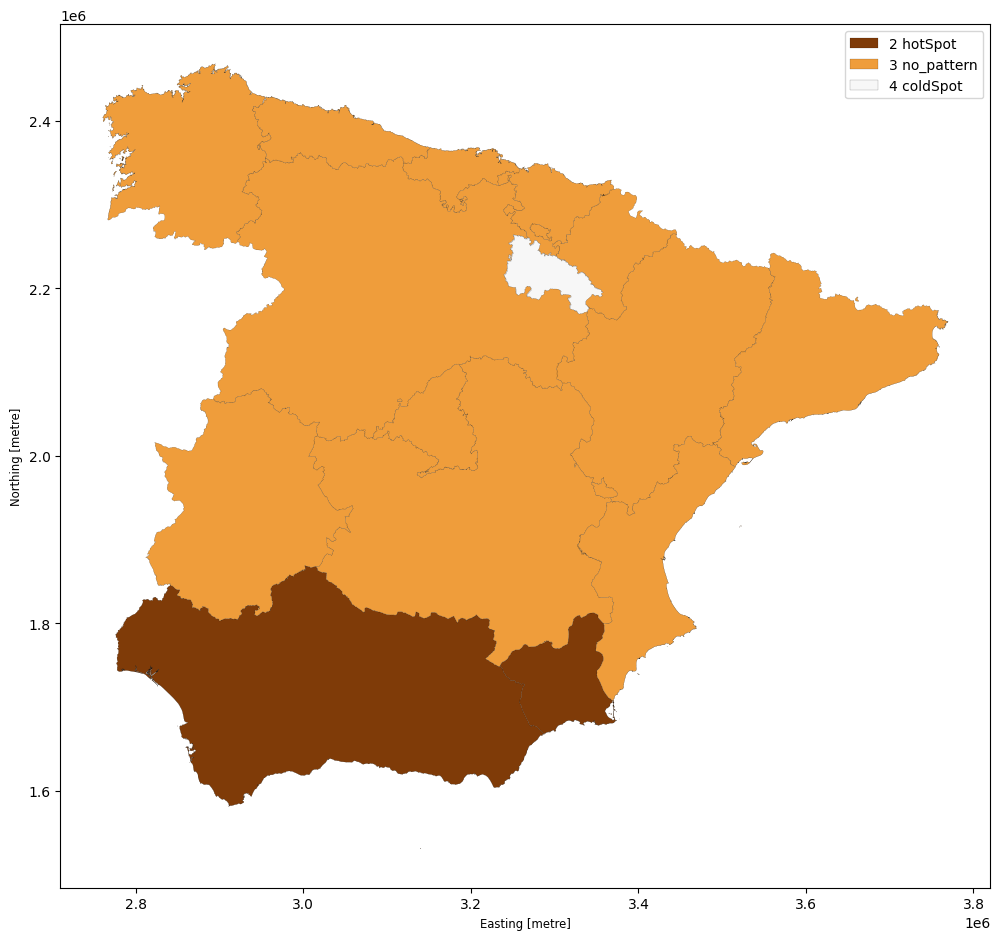

In [520]:
esp_selected.plot(
    column='HS_lisa_knn4',
    categorical=True,
    cmap=myColMap,
    linewidth=0.1,
    edgecolor='k',
    legend=True,
    figsize=(12, 12)
)

**Within zone of influence**

In [522]:
import numpy as np
from scipy.spatial.distance import cdist

points = esp_selected.representative_point()

coords = np.column_stack((points.x, points.y))

dist_matrix = cdist(coords, coords)
np.fill_diagonal(dist_matrix, np.inf)

nearest_distances = dist_matrix.min(axis=1)

pd.Series(nearest_distances).describe()

,0
count,15.000000
mean,148943.735621
std,52616.318085
min,74937.357857
25%,121980.914715
50%,152882.074445
75%,160535.644782
max,238846.747776


In [524]:
band250k = Graph.build_distance_band(
    points,
    threshold=250000
)

In [525]:
band50k = band50k.transform("r")

In [526]:
len(band50k.isolates)


15

In [529]:
lisa_band250k = esda.Moran_Local(
    esp_selected['pobreza'],
    band250k
)

In [531]:
esp_selected['HS_lisa_band250k'] = lisa_band250k.get_cluster_labels(crit_value=0.05)

In [532]:
esp_selected['HS_lisa_band250k'].value_counts()

,count
HS_lisa_band250k,
Insignificant,8
Low-Low,4
High-High,2
High-Low,1


In [533]:
oldLabels = ['Insignificant', 'Low-Low', 'High-High', 'High-Low', 'Low-High']

newLabels = [
    '3 no_pattern',
    '4 coldSpot',
    '2 hotSpot',
    '1 hotOutlier',
    '5 coldOutlier'
]

labels = dict(zip(oldLabels, newLabels))

esp_selected.replace({'HS_lisa_band50k': labels}, inplace=True)

**CUARTO MAPA**

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

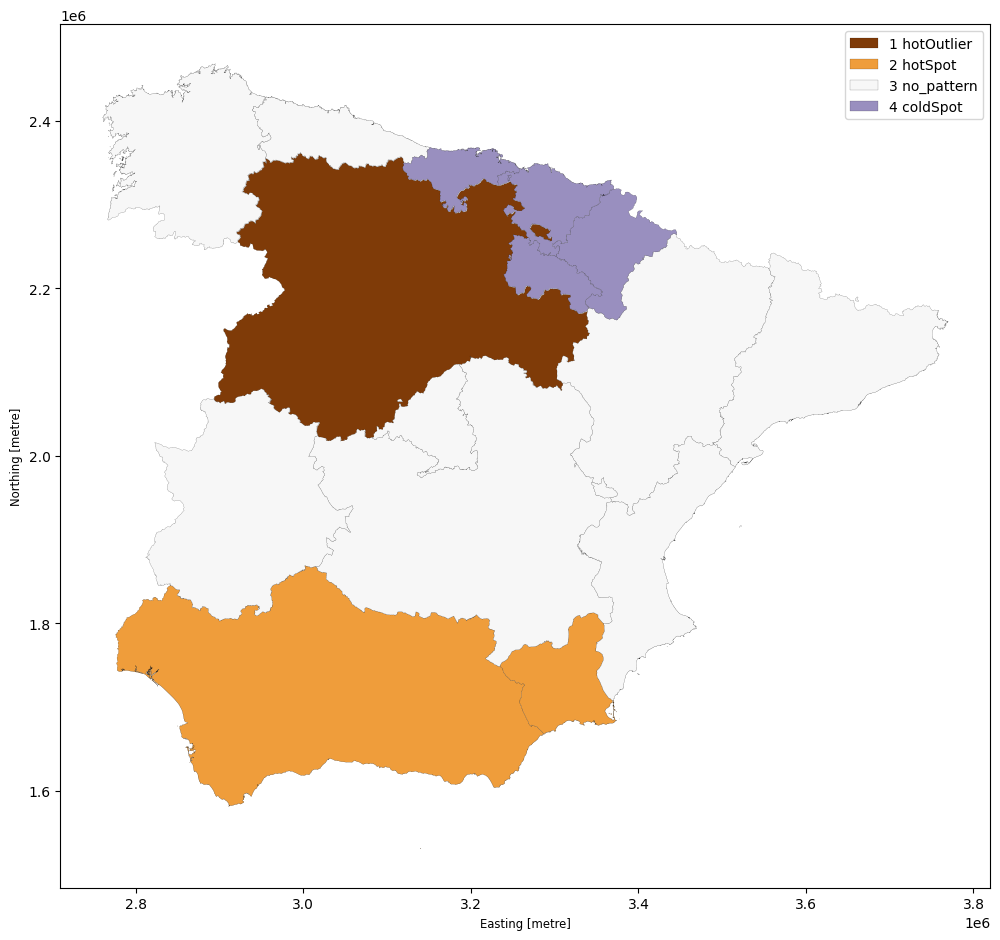

In [534]:
esp_selected.plot(
    column='HS_lisa_band50k',
    categorical=True,
    cmap=myColMap,
    linewidth=0.1,
    edgecolor='k',
    legend=True,
    figsize=(12, 12)
)

#EXPLICACIÓN